## Selecting Encoders

In [4]:
from sentence_transformers import SentenceTransformer

# Load Cross-Encoder
cross_encoder_path = "cross-encoder/ms-marco-MiniLM-L-6-v2"
cross_encoder = SentenceTransformer(cross_encoder_path)

# Load Dual-Encoder
dual_encoder_path = "sentence-transformers/multi-qa-MiniLM-L6-cos-v1"
dual_encoder = SentenceTransformer(dual_encoder_path)

No sentence-transformers model found with name cross-encoder/ms-marco-MiniLM-L-6-v2. Creating a new one with mean pooling.


## Selecting query, relevant and irrelevant document

In [5]:
from importlib import reload
import TRECCASTeval as trec
import OpenSearchSimpleAPI as osearch
from retrieval_methods.LMD import LMD_Retrieval

import pprint as pp

osearch = reload(osearch)
trec = reload(trec)

lmd = LMD_Retrieval

opensearch = osearch.OSsimpleAPI()
test_bed = trec.ConvSearchEvaluation()
conv_topics = test_bed.train_topics

In [6]:
conv_topic_idx = 0

topic = conv_topics[conv_topic_idx]

turn = topic['turn'][7]
turn_id = turn['number']
utterance = turn['raw_utterance']
print(utterance)


result = lmd.retrieve_fun(opensearch,utterance,200)

What the difference between a PA and a nurse practitioner?
['MARCO_6311185', 'MARCO_7090806', 'MARCO_2849832', 'MARCO_3600884', 'MARCO_7514658', 'MARCO_8579371', 'MARCO_888704', 'MARCO_1908383', 'MARCO_168924', 'MARCO_3144856', 'MARCO_6312729', 'MARCO_4077804', 'MARCO_5407409', 'MARCO_7496118', 'MARCO_3984229', 'MARCO_1908384', 'MARCO_7446928', 'CAR_436ad602db45c2c05a6f1d2b9461f20e8400e60a', 'MARCO_5893872', 'MARCO_5699123', 'MARCO_3951096', 'MARCO_5673918', 'MARCO_6816116', 'MARCO_615449', 'CAR_a1abdc7279a2178f62a20792a69b6bdb95731eea', 'MARCO_1505116', 'MARCO_3984224', 'MARCO_6607048', 'MARCO_6244208', 'MARCO_2904127', 'MARCO_2307794', 'MARCO_4225982', 'MARCO_6311397', 'MARCO_4003509', 'MARCO_364098', 'MARCO_8407876', 'MARCO_4014355', 'MARCO_8716240', 'MARCO_2483667', 'MARCO_5787541', 'MARCO_291620', 'MARCO_7560829', 'MARCO_8503215', 'MARCO_3768527', 'MARCO_2596754', 'MARCO_1827628', 'MARCO_6607056', 'MARCO_6607051', 'MARCO_7342285', 'MARCO_8824030', 'MARCO_3860555', 'MARCO_4518595',

In [7]:
print(result)

                                              _id     _score  \
0                                   MARCO_6311185 -37.655107   
1                                   MARCO_7090806 -39.050118   
2                                   MARCO_2849832 -39.341187   
3                                   MARCO_7514658 -39.952613   
4                                   MARCO_3600884 -43.978987   
..                                            ...        ...   
195                                 MARCO_4847842 -69.825960   
196                                   MARCO_62926 -69.973198   
197                                 MARCO_5604435 -70.994448   
198  CAR_4d4e149f7b51d26af25203d7b69b6dae853f05b9 -73.007611   
199  CAR_eac4c13d758d330e97e60846c09b7df81eb1a404 -73.628529   

                                      _source.doc  
0                                   MARCO_6311185  
1                                   MARCO_7090806  
2                                   MARCO_2849832  
3                      

In [8]:
top_doc = result.iloc[0]
top_doc_body = opensearch.get_doc_body(top_doc._id)
print("TOP DOCUMENT:")
print("-" + top_doc_body)

bottom_doc = result.iloc[199]
bottom_doc_body = opensearch.get_doc_body(bottom_doc._id)
print("BOTTOM DOCUMENT:")
print("-" + bottom_doc_body)



TOP DOCUMENT:
-The real debate is in the difference between a PA and a Nurse Practitioner (NP). A Nurse Practitioner is a nurse that has completed a master's degree (soon to be doctorate) in advanced practice nursing.In other words, they can diagnose and treat without the supervision of a doctor.Differences. Educational Path.he real debate is in the difference between a PA and a Nurse Practitioner (NP). A Nurse Practitioner is a nurse that has completed a master's degree (soon to be doctorate) in advanced practice nursing. In other words, they can diagnose and treat without the supervision of a doctor. Differences. Educational Path.
BOTTOM DOCUMENT:
-There are performance differences and similarities between this class and other wheelchair classes. A 1999 study of discus throwers found that for F5 to F8 discus throwers, the upper arm tends to be near horizontal at the moment of release of the discus. F5 to F7 discus throwers have greater angular speed of the shoulder girdle during rele

## 3

In [9]:
import numpy as np

from transformers import AutoTokenizer, AutoConfig, AutoModelForSequenceClassification
import torch
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
%matplotlib notebook
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('ggplot')


In [10]:
CLS_token = "[CLS]"
SEP_token = "[SEP]"

In [13]:
cross_encoder_tokenizer = AutoTokenizer.from_pretrained(cross_encoder_path)
cross_encoder_config = AutoConfig.from_pretrained(cross_encoder_path, output_hidden_states=True, output_attentions=True)
cross_encoder_model = AutoModelForSequenceClassification.from_pretrained(cross_encoder_path, config=cross_encoder_config)

In [14]:
cross_encoder_model

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 384, padding_idx=0)
      (position_embeddings): Embedding(512, 384)
      (token_type_embeddings): Embedding(2, 384)
      (LayerNorm): LayerNorm((384,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-5): 6 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=384, out_features=384, bias=True)
              (key): Linear(in_features=384, out_features=384, bias=True)
              (value): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=384, out_features=384, bias=True)
              (LayerNorm): LayerNorm((384,), eps=1e-1

In [114]:
#cross_encoder_POS = cross_encoder_tokenizer(f"{utterance} [SEP] {top_doc_body}", truncation=True, padding=True, return_tensors="pt")
#cross_encoder_NEG = cross_encoder_tokenizer(f"{utterance} [SEP] {bottom_doc_body}", truncation=True, padding=True, return_tensors="pt")
cross_encoder_POS = cross_encoder_tokenizer(utterance,top_doc_body, return_tensors='pt', add_special_tokens=True, max_length = 512, padding=True, truncation = True)
cross_encoder_NEG = cross_encoder_tokenizer(utterance,bottom_doc_body, return_tensors='pt', add_special_tokens=True, max_length = 512, padding=True, truncation = True)


In [70]:
dual_encoder_tokenizer = AutoTokenizer.from_pretrained(dual_encoder_path)
dual_encoder_config = AutoConfig.from_pretrained(dual_encoder_path, output_hidden_states=True, output_attentions=True)
dual_encoder_model = AutoModelForSequenceClassification.from_pretrained(dual_encoder_path, config=dual_encoder_config)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at sentence-transformers/multi-qa-MiniLM-L6-cos-v1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [27]:
dual_encoder_model

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 384, padding_idx=0)
      (position_embeddings): Embedding(512, 384)
      (token_type_embeddings): Embedding(2, 384)
      (LayerNorm): LayerNorm((384,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-5): 6 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=384, out_features=384, bias=True)
              (key): Linear(in_features=384, out_features=384, bias=True)
              (value): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=384, out_features=384, bias=True)
              (LayerNorm): LayerNorm((384,), eps=1e-1

In [115]:
query_embedding = dual_encoder.encode(utterance, convert_to_tensor=True)
relevant_embedding = dual_encoder.encode(top_doc_body, convert_to_tensor=True)
unrelevant_embedding = dual_encoder.encode(bottom_doc_body, convert_to_tensor=True)

## 3

In [118]:
print(cross_encoder_tokenizer.decode(cross_encoder_POS["input_ids"][0]))
input_ids_POS = cross_encoder_POS['input_ids']
input_ids_POS_list = input_ids_POS[0].tolist()
input_tokens_POS_list = cross_encoder_tokenizer.convert_ids_to_tokens(input_ids_POS_list)
print(input_tokens_POS_list)

[CLS] what the difference between a pa and a nurse practitioner? [SEP] the real debate is in the difference between a pa and a nurse practitioner ( np ). a nurse practitioner is a nurse that has completed a master's degree ( soon to be doctorate ) in advanced practice nursing. in other words, they can diagnose and treat without the supervision of a doctor. differences. educational path. he real debate is in the difference between a pa and a nurse practitioner ( np ). a nurse practitioner is a nurse that has completed a master's degree ( soon to be doctorate ) in advanced practice nursing. in other words, they can diagnose and treat without the supervision of a doctor. differences. educational path. [SEP]
['[CLS]', 'what', 'the', 'difference', 'between', 'a', 'pa', 'and', 'a', 'nurse', 'practitioner', '?', '[SEP]', 'the', 'real', 'debate', 'is', 'in', 'the', 'difference', 'between', 'a', 'pa', 'and', 'a', 'nurse', 'practitioner', '(', 'np', ')', '.', 'a', 'nurse', 'practitioner', 'is', 

In [119]:
res_POS = "\n".join("{} \t {}".format(x, y) for x, y in zip(input_ids_POS_list, input_tokens_POS_list))
print(res_POS)

101 	 [CLS]
2054 	 what
1996 	 the
4489 	 difference
2090 	 between
1037 	 a
6643 	 pa
1998 	 and
1037 	 a
6821 	 nurse
18742 	 practitioner
1029 	 ?
102 	 [SEP]
1996 	 the
2613 	 real
5981 	 debate
2003 	 is
1999 	 in
1996 	 the
4489 	 difference
2090 	 between
1037 	 a
6643 	 pa
1998 	 and
1037 	 a
6821 	 nurse
18742 	 practitioner
1006 	 (
27937 	 np
1007 	 )
1012 	 .
1037 	 a
6821 	 nurse
18742 	 practitioner
2003 	 is
1037 	 a
6821 	 nurse
2008 	 that
2038 	 has
2949 	 completed
1037 	 a
3040 	 master
1005 	 '
1055 	 s
3014 	 degree
1006 	 (
2574 	 soon
2000 	 to
2022 	 be
8972 	 doctorate
1007 	 )
1999 	 in
3935 	 advanced
3218 	 practice
8329 	 nursing
1012 	 .
1999 	 in
2060 	 other
2616 	 words
1010 	 ,
2027 	 they
2064 	 can
22939 	 dia
26745 	 ##gno
3366 	 ##se
1998 	 and
7438 	 treat
2302 	 without
1996 	 the
10429 	 supervision
1997 	 of
1037 	 a
3460 	 doctor
1012 	 .
5966 	 differences
1012 	 .
4547 	 educational
4130 	 path
1012 	 .
2002 	 he
2613 	 real
5981 	 debate
2

In [128]:
with torch.no_grad():
    outputs = cross_encoder_model(**cross_encoder_POS)

In [168]:
def display_scatterplot(data, words):

    if data.shape[1] == 2:
        twodim = data
    else:
        pca = PCA()
        pca.fit(data)
        twodim = pca.transform(data)[:,:2]
    
    plt.style.use('default') # https://matplotlib.org/3.5.1/gallery/style_sheets/style_sheets_reference.html
    plt.figure(figsize=(6,6))
    plt.scatter(twodim[:,0], twodim[:,1], edgecolors='k', c='r')
    for word, (x,y) in zip(words, twodim):
        plt.text(x+0.05, y+0.05, word)

    return

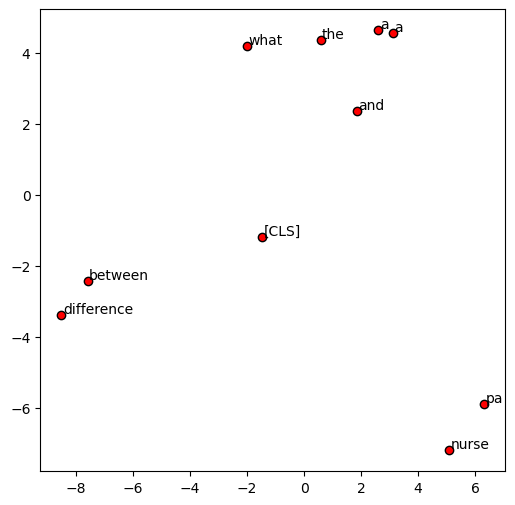

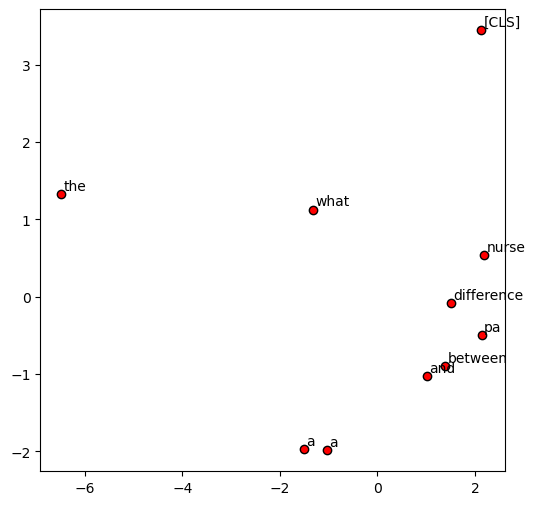

In [185]:
first_layer_embeddings = outputs.hidden_states[0][0][:10].detach().numpy()
last_layer_embeddings = outputs.hidden_states[-1][0][:10].detach().numpy()


display_scatterplot(first_layer_embeddings, input_tokens_POS_list[:10])
display_scatterplot(last_layer_embeddings, input_tokens_POS_list[:10])

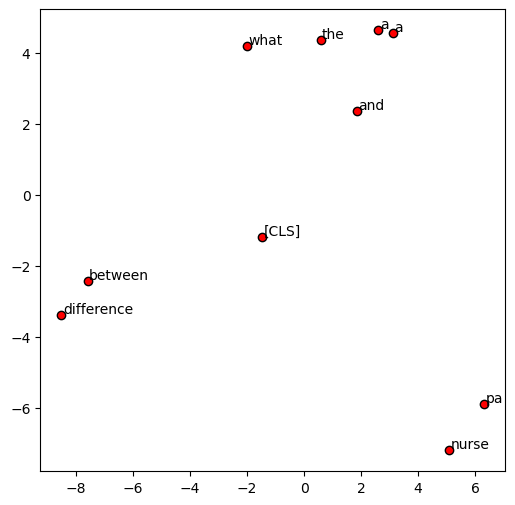

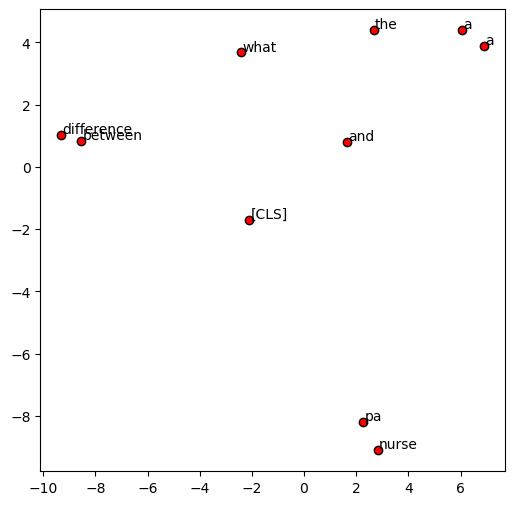

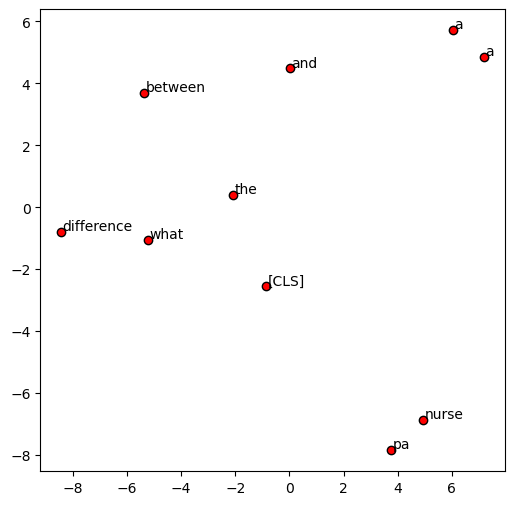

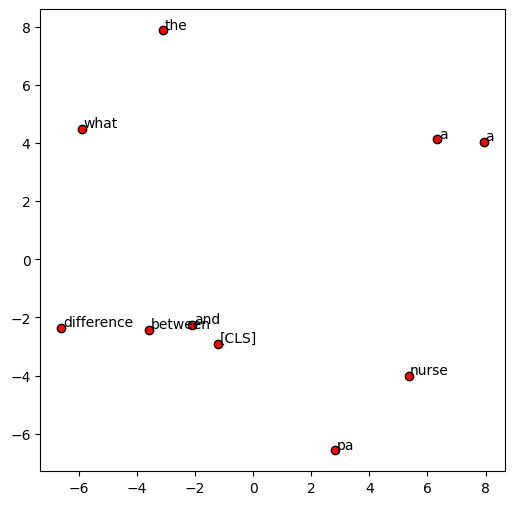

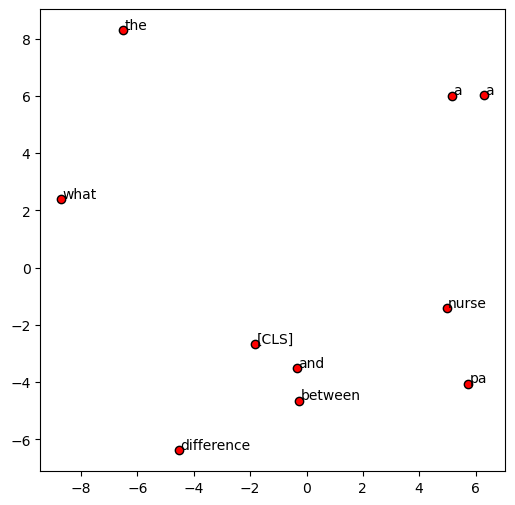

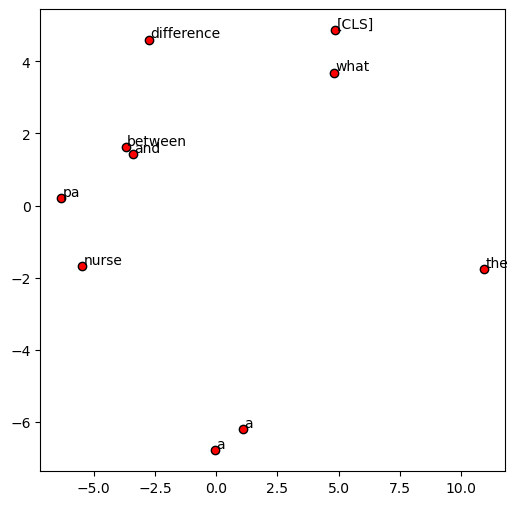

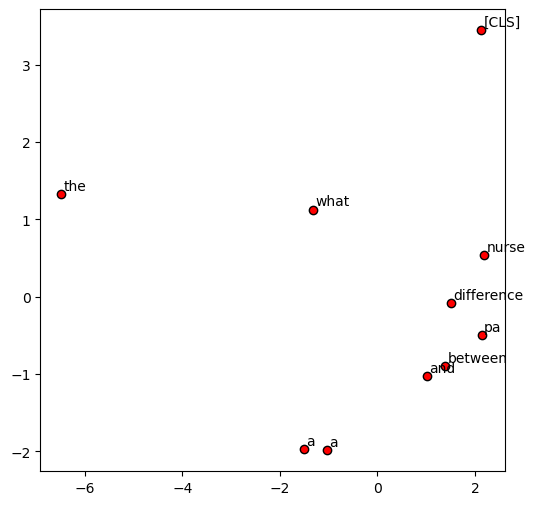

In [187]:
for layer_idx, layber_embedding in enumerate(outputs.hidden_states):
    layber_embeddings_10 = layber_embedding[0][:10].detach().numpy()
    display_scatterplot(layber_embeddings_10, input_tokens_POS_list[:10])
    